In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [3]:
Gam_quark = np.linspace(2.5,3.5,100)
n_quark = np.linspace(0.5344,2.3,20)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,20)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

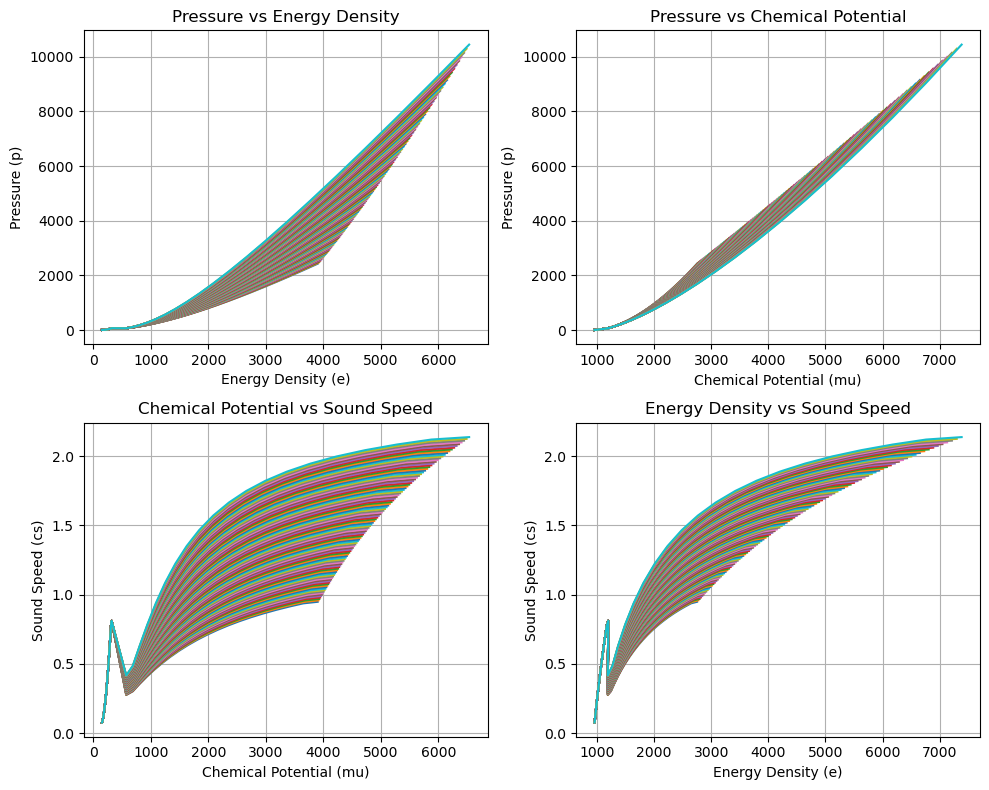

In [4]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
# Initialize empty lists to store concatenated data
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = [], [], [], [], [], []

# Loop through Gam_quark to plot curves for each value of g_quark
for g_quark in Gam_quark:
    K_quark = p / (n_quark[0] ** g_quark)
    m0_quark = (e - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

    # Hadronic EOS
    p_had = P_from_nb(n_had, K_had, Gam_had)
    mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
    e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
    cs_had = np.gradient(p_had, e_had)

    # Quark EOS
    p_quark = P_from_nb(n_quark, K_quark, g_quark)
    mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
    e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
    cs_quark = np.gradient(p_quark, e_quark)

    # Concatenate hadronic and quark data
    e_combined = np.concatenate((e_had, e_quark))
    p_combined = np.concatenate((p_had, p_quark))
    mu_combined = np.concatenate((mu_had, mu_quark))
    cs_combined = np.concatenate((cs_had, cs_quark))

    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit.append(p_quark[0])
    mu_crit.append(mu_quark[0])


# After the loop, plot concatenated data
for i in range(len(Gam_quark)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 1].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 0].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [5]:
P_crit_1 = p*(1+0.01)
P_crit_2 = p*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [6]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
a_optimal_1 = []
b_optimal_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[0], P  # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)

    # Find the index of the minimum distance across all runs
    index = min_distances.argmin()

    # Save a specific optimal value to P_all based on index
    P_all.append(P_optimal[index])
    P_all_1.append(P_optimal[0])
    P_max_points.append(min_distance_points[index])
    P_max_points_1.append(min_distance_points[0])
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)

In [7]:
list = np.linspace(0,120,5)

In [8]:
list=list[:-1]

In [9]:
list

array([ 0., 30., 60., 90.])

In [10]:
len(e_total)

100

In [11]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)


from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [12]:
import numpy as np

def concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1):
    eos_final = []
    for i in range(len(mu_crit)):

        x2, y2 = mu_crit[i], P_all_1[i]  # Critical point
        a_op = a_optimal_1[i][0]
        b_op = b_optimal_1[i][0]        
        # Define quadratic function
        def quadratic(x):
            return a_op * (x - x2)**2 + b_op * (x - x2) + y2
        
        # Generate smooth quadratic fit until quark EOS
        p_fit = quadratic(mu_total[i])
        index = find_first_larger_index(mu_total[i], P_max_points_1[i][0])
        p_t = np.concatenate((p_fit[:index],p_total[i][index:]))
        eos_final.append((p_t, mu_total[i]))
        
    return eos_final

In [13]:
eos = concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1)

In [14]:
mu_total[99]

array([ 956.58252996,  960.37468538,  964.7630495 ,  969.80618257,
        975.5652709 ,  982.10411722,  989.48913151,  997.78932224,
       1007.076288  , 1017.42420946, 1028.90984173, 1041.6125069 ,
       1055.614087  , 1070.9990171 , 1087.85427873, 1106.2693935 ,
       1126.3364169 , 1148.14993237, 1171.80704548, 1197.40737836,
       1188.86040419, 1270.4606053 , 1372.38488165, 1496.08899599,
       1642.93708086, 1814.21706316, 2011.15218625, 2234.90988781,
       2486.60881338, 2767.32447197, 3078.09387591, 3419.9194036 ,
       3793.77205602, 4200.59423261, 4641.30212021, 5116.78776682,
       5627.9208953 , 6175.55050082, 6760.50626618, 7383.59982311])

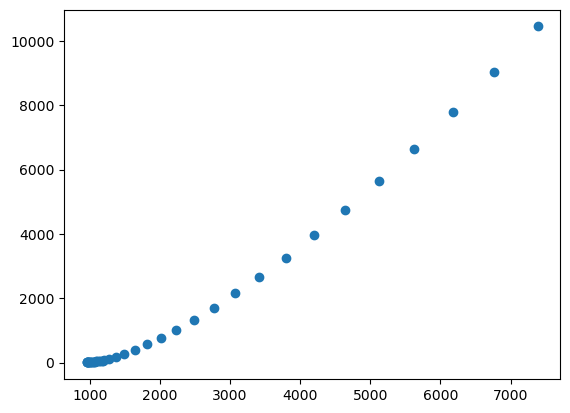

In [15]:
plt.scatter(mu_total[99],p_total[99])

In [16]:
P_max_points_1[99]

(1496.0889959910808, 274.5856701875312)

In [17]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [18]:
len(eos)

100

In [19]:
len(eos[27][1])==len(eos[27][0])

True

In [20]:
import numpy as np

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    return n_quad, e_quad

# Lists to store results
n_quad_list = []
e_quad_list = []
# Loop through eos data
for i in range(len(eos)):
    if len(eos[i][1])==len(eos[i][0]) :
        n_quad, e_quad = compute_n_e(eos[i][0], eos[i][1])
        n_quad_list.append(n_quad)
        e_quad_list.append(e_quad)
    else:
        n_quad_list.append([0])
        e_quad_list.append([0])

In [21]:
len(e_quad_list)==len(e_total)

True

In [51]:
r, m, c, l = [], [], [], []
r1, m1, c1, l1 = [], [], [], []

In [52]:
r, m, c, l = generate_mr_curve(e_total[40], p_total[40])
r1, m1, c1, l1 = generate_mr_curve(e_quad_list[40], p_total[40])

In [27]:
p_total[40]

array([2.17013908e+00, 2.79324934e+00, 3.55125817e+00, 4.46481130e+00,
       5.55653146e+00, 6.85110490e+00, 8.37536764e+00, 1.01583914e+01,
       1.22315693e+01, 1.46287012e+01, 1.73860788e+01, 2.05425707e+01,
       2.41397069e+01, 2.82217630e+01, 3.28358448e+01, 3.80319723e+01,
       4.38631627e+01, 5.03855151e+01, 5.76582930e+01, 6.57440078e+01,
       6.31770000e+01, 1.00637256e+02, 1.50305919e+02, 2.13807388e+02,
       2.92745955e+02, 3.88708334e+02, 5.03265641e+02, 6.37974986e+02,
       7.94380786e+02, 9.74015849e+02, 1.17840231e+03, 1.40905240e+03,
       1.66746918e+03, 1.95514710e+03, 2.27357253e+03, 2.62422427e+03,
       3.00857392e+03, 3.42808631e+03, 3.88421981e+03, 4.37842663e+03])

In [29]:
len(e_quad_list[40])

39

In [47]:
cs_quad_list =[]
for i in range(len(p_total)):
    cs_quad_list.append(np.gradient(p_total[i][:-1],e_quad_list[i]))

In [ ]:
import numpy as np

# Initialize indices as None
i_c, i_c1 = None, None

# Iterate over the valid range
for i in range(len(e_total[0]) - 1):
    # Check if cs_total[40][i] > 1 and store the first occurrence
    if cs_total[40][i] > 1 and i_c is None:
        i_c = i
    
    # Check if cs_quad_list[i] > 1 and store the first occurrence
    elif cs_quad_list[40][i] > 1 and i_c1 is None:
        i_c1 = i

    # Exit loop early if both indices are found
    if i_c is not None and i_c1 is not None:
        break

print(f"i_c = {i_c}, i_c1 = {i_c1}")

i_c = 30, i_c1 = 31


In [39]:
i_c1

31

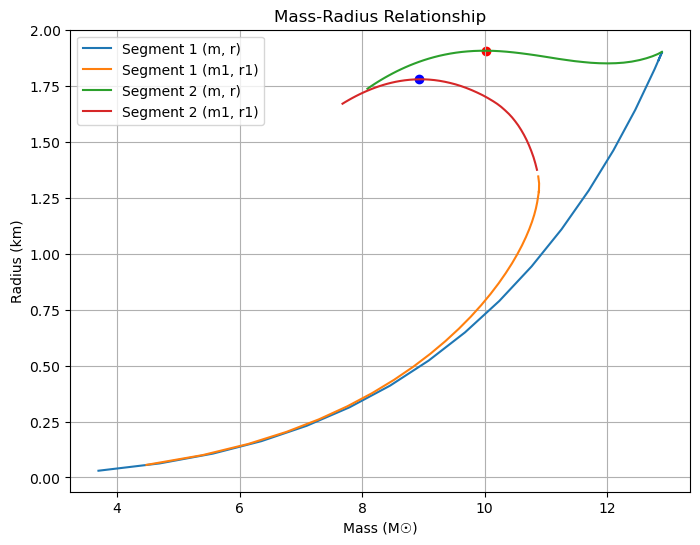

In [45]:
plt.figure(figsize=(8, 6))

# Plot the first and second segments for both sets
plt.plot(r[:i_c], m[:i_c], label="Segment 1 (m, r)")
plt.plot(r1[:i_c1], m1[:i_c1], label="Segment 1 (m1, r1)")
plt.plot(r[i_c:], m[i_c:], label="Segment 2 (m, r)")
plt.plot(r1[i_c1:], m1[i_c1:], label="Segment 2 (m1, r1)")
plt.scatter(r[np.argmax(m)], m[np.argmax(m)], color='red', marker='o')
plt.scatter(r1[np.argmax(m1)], m1[np.argmax(m1)], color='blue', marker='o')

# Labels and legend
plt.xlabel("Mass (M☉)")
plt.ylabel("Radius (km)")
plt.legend()
plt.title("Mass-Radius Relationship")
plt.grid(True)

plt.show()

i_c = 25, i_c1 = 26


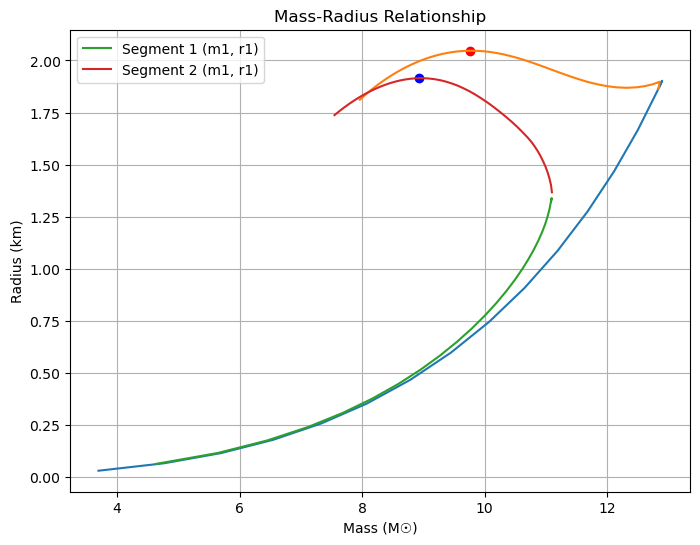

In [50]:
import matplotlib.pyplot as plt
import numpy as np

def plot_mass_radius(index):
    # Generate mass-radius curves
    r, m, c, l = generate_mr_curve(e_total[index], p_total[index])
    r1, m1, c1, l1 = generate_mr_curve(e_quad_list[index], p_total[index])

    # Initialize indices as None
    i_c, i_c1 = None, None

    # Find the first index where cs_total or cs_quad_list exceeds 1
    for i in range(len(e_total[0]) - 1):
        if cs_total[index][i] > 1 and i_c is None:
            i_c = i
        if cs_quad_list[index][i] > 1 and i_c1 is None:
            i_c1 = i

        # Exit loop early if both indices are found
        if i_c is not None and i_c1 is not None:
            break

    print(f"i_c = {i_c}, i_c1 = {i_c1}")

    # Create the plot
    plt.figure(figsize=(8, 6))

    # Plot the first and second segments for both sets
    plt.plot(r[:i_c], m[:i_c])  # First segment (m, r)
    plt.plot(r[i_c:], m[i_c:])  # Second segment (m, r)

    plt.plot(r1[:i_c1], m1[:i_c1], label="Segment 1 (m1, r1)")
    plt.plot(r1[i_c1:], m1[i_c1:], label="Segment 2 (m1, r1)")

    # Scatter points for maximum mass values
    plt.scatter(r[np.argmax(m)], m[np.argmax(m)], color='red', marker='o')
    plt.scatter(r1[np.argmax(m1)], m1[np.argmax(m1)], color='blue', marker='o')

    # Labels and legend
    plt.xlabel("Mass (M☉)")
    plt.ylabel("Radius (km)")
    plt.legend()
    plt.title("Mass-Radius Relationship")
    plt.grid(True)

    plt.show()

# Example usage
plot_mass_radius(90)

In [71]:
radii_1, masses_1, compacts_1, love_nums_1 = [0]*len(list), [0]*len(list), [0]*len(list), [0]*len(list)

In [74]:
for i in range(len(list)):
    j = int(list[i])
    e_arr = e_total[j]
    p_arr = p_total[j]
    radii_1[i], masses_1[i], compacts_1[i], love_nums_1[i] = generate_mr_curve(e_arr, p_arr)

In [80]:
radii, masses, compacts, love_nums = [0]*len(list), [0]*len(list), [0]*len(list), [0]*len(list)

In [ ]:
type(e_quad)

list

In [82]:
len(e_quad_list)

73

In [102]:
list

array([30., 60., 90.])

In [100]:
for i in range(len(list)):
    j = int(list[i])
    e_arr = e_quad_list[j]
    p_arr = p_total[j]
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(e_arr, p_arr)

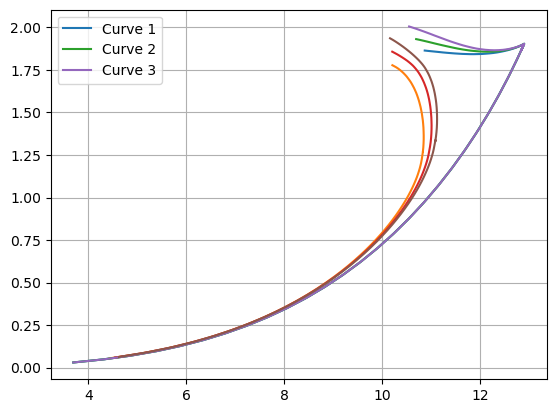

In [101]:
for i in range(len(list)):
    plt.plot(radii_1[i],masses_1[i], label=f"Curve {i+1}")
    plt.plot(radii[i],masses[i])
plt.grid()
plt.legend()

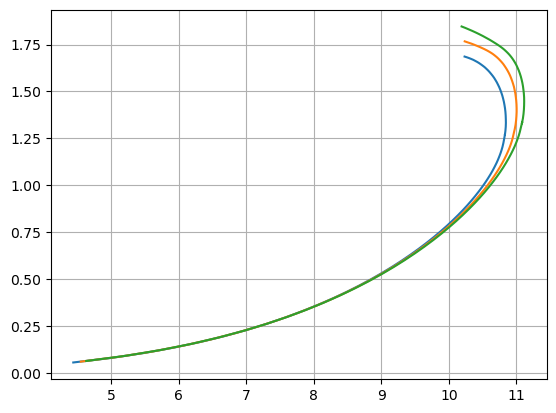

In [85]:
for i in range(len(list)):
    plt.plot(radii[i],masses[i])
plt.grid()

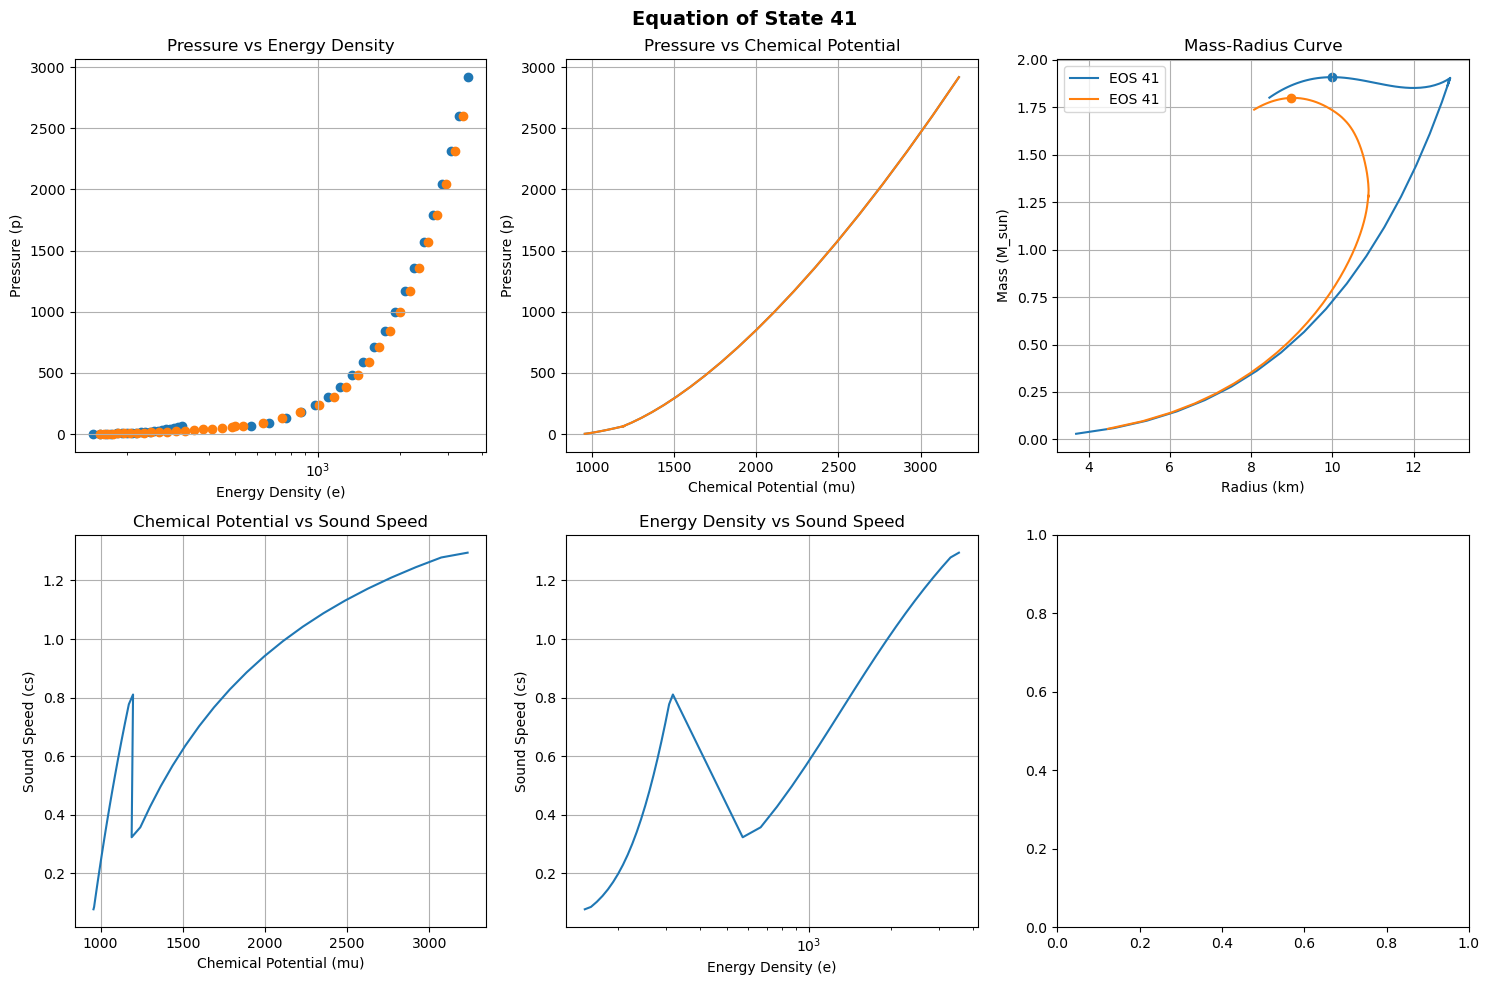

1.9075921162853524
1.7983222568296342


In [154]:
import matplotlib.pyplot as plt

def plot_eos(i, e_total, p_total, mu_total, cs_total, radii_1, masses_1):
    """
    Plots various properties of the Equation of State (EOS) for a given index.

    Parameters:
    - i: int, index of the EOS to plot
    - e_total: list of energy density values for different EOSs
    - p_total: list of pressure values for different EOSs
    - mu_total: list of chemical potential values for different EOSs
    - cs_total: list of sound speed values for different EOSs
    - generate_mr_curve: function that generates mass-radius data for an EOS
    """

    # Create a 2x3 grid of subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])
    axes[0, 0].scatter(e_quad_list[i], p_total[i][:-1])
    axes[0, 0].set_title('Pressure vs Energy Density')
    axes[0, 0].set_xlabel('Energy Density (e)')
    axes[0, 0].set_ylabel('Pressure (p)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].grid(True)

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])
    axes[0, 1].plot(eos[i][1], p_total[i])
    axes[0, 1].set_title('Pressure vs Chemical Potential')
    axes[0, 1].set_xlabel('Chemical Potential (mu)')
    axes[0, 1].set_ylabel('Pressure (p)')
    axes[0, 1].grid(True)

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])
    axes[1, 0].set_title('Chemical Potential vs Sound Speed')
    axes[1, 0].set_ylabel('Sound Speed (cs)')
    axes[1, 0].set_xlabel('Chemical Potential (mu)')
    axes[1, 0].grid(True)

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])
    axes[1, 1].set_title('Energy Density vs Sound Speed')
    axes[1, 1].set_ylabel('Sound Speed (cs)')
    axes[1, 1].set_xlabel('Energy Density (e)')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(True)

    # Plot 5: Mass-Radius (M-R) Curve
    radii_111, masses_111, _, _ = generate_mr_curve(e_total[i], p_total[i])
    radii_112, masses_112, _, _ = generate_mr_curve(e_quad_list[i], p_total[i])
    axes[0, 2].plot(radii_111, masses_111, label=f'EOS {i+1}')
    axes[0, 2].scatter(radii_111[np.argmax(masses_111)], masses_111[np.argmax(masses_111)])
    axes[0, 2].scatter(radii_112[np.argmax(masses_112)], masses_112[np.argmax(masses_112)])
    axes[0, 2].plot(radii_112, masses_112, label=f'EOS {i+1}')
    axes[0, 2].set_title('Mass-Radius Curve')
    axes[0, 2].set_xlabel('Radius (km)')
    axes[0, 2].set_ylabel('Mass (M_sun)')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    # Adjust layout and show the plot
    plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(max(masses_111))
    print(max(masses_112))

plot_eos(i=40, e_total=e_total, p_total=p_total, mu_total=mu_total, cs_total=cs_total, radii_1=radii_1, masses_1=masses_1)

In [153]:
max(masses_111)

NameError: name 'masses_111' is not defined

In [128]:
p_total[90]

array([  2.17013908,   2.79324934,   3.55125817,   4.4648113 ,
         5.55653146,   6.8511049 ,   8.37536764,  10.1583914 ,
        12.2315693 ,  14.62870119,  17.38607883,  20.54257074,
        24.13970687,  28.22176298,  32.83584485,  38.03197225,
        43.86316273,  50.38551513,  57.65829302,  65.74400784,
        63.177     ,  73.61053341,  85.20635597,  98.0369051 ,
       112.17587417, 127.69818238, 144.67994636, 163.19845362,
       183.3321374 , 205.16055305, 228.76435558, 254.22527839,
       281.62611316, 311.05069058, 342.58386216, 376.31148269,
       412.32039365, 450.69840728, 491.53429124, 534.91775407])

In [125]:
p_total[60]==eos[60][0]

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True])

In [105]:
len(radii_1)

3

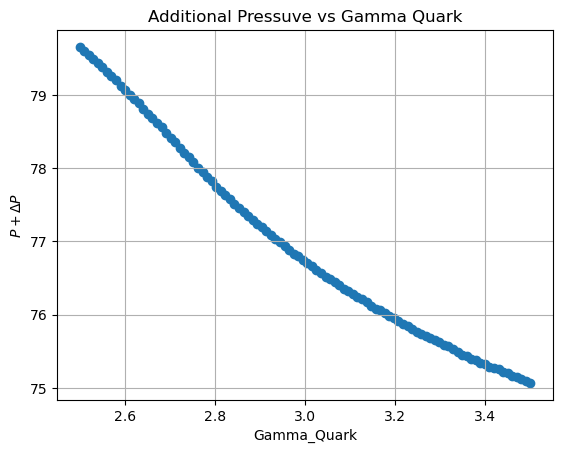

In [19]:
plt.scatter(Gam_quark,P_all_1);
plt.title("Additional Pressuve vs Gamma Quark")
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'$P + \Delta P $');
plt.show();

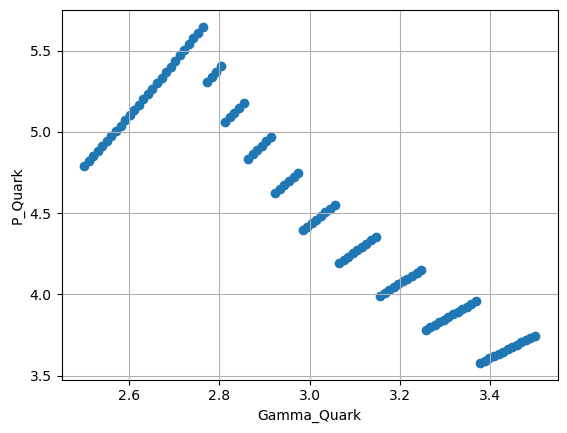

In [22]:
plt.scatter(Gam_quark,[y for x,y in P_max_points_1]/P_crit[0]);
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'P_Quark');
plt.show();

In [21]:
def quadratic_fit(x, y):
    """
    Fit a quadratic curve to the given data points (x, y).

    Parameters:
        x (array-like): The input data points for the x-axis.
        y (array-like): The input data points for the y-axis.

    Returns:
        tuple: A tuple containing:
            - coefficients (a, b, c) for the quadratic curve y = ax^2 + bx + c
            - a function to compute fitted y-values for any input x.
    """
    # Perform quadratic curve fitting
    coefficients = np.polyfit(x, y, deg=2)  # Returns [a, b, c] for y = ax^2 + bx + c
    
    # Create a function for the fitted curve
    def fitted_curve(x_values):
        return coefficients[0] * x_values**2 + coefficients[1] * x_values + coefficients[2]
    
    return coefficients, fitted_curve

Quadratic Coefficients (a, b, c): [  2.71768221 -20.9600586  115.16462266]


<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14897/816275865.py:21: SyntaxWarning: invalid escape sequence '\G'
  plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14897/816275865.py:21: SyntaxWarning: invalid escape sequence '\G'
  plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)


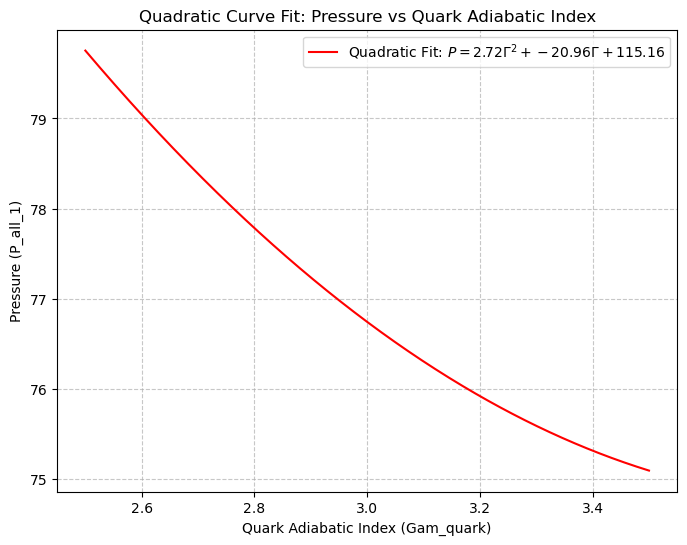

In [24]:
Gam_quark = np.array(Gam_quark)  # Replace with your actual data
P_all_1 = np.array(P_all_1)      # Replace with your actual data

# Check if their lengths match
if len(Gam_quark) != len(P_all_1):
    raise ValueError("Gam_quark and P_all_1 must have the same number of elements.")

# Get quadratic fit
coeffs, fit_fn = quadratic_fit(Gam_quark, P_all_1)

# Print the coefficients
print("Quadratic Coefficients (a, b, c):", coeffs)

# Generate fine-grained points for the fitted curve
Gam_fine = np.linspace(min(Gam_quark), max(Gam_quark), 500)  # Fine-grained x values
P_fitted = fit_fn(Gam_fine)

# Plot the original data and the fitted curve
plt.figure(figsize=(8, 6))
#plt.scatter(Gam_quark, P_all_1, color='blue', label='Original Data', zorder=3)
plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)
plt.xlabel('Quark Adiabatic Index (Gam_quark)')
plt.ylabel('Pressure (P_all_1)')
plt.title('Quadratic Curve Fit: Pressure vs Quark Adiabatic Index')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()